# Milestone 2 Analysis

## Task 1: Optimized vs. naive order flights

## Task 5: Payload box hover

### How mocap reaches the controller

With the flow deck removed, the motion capture system is the only source of position. Each pose goes through these steps:

1. **Qualisys** tracks the marker deck at 100 Hz and streams its position and orientation (as a quaternion) to the laptop.
2. **The laptop** (`QualisysClient` in the flight script) logs every pose, and forwards each one to the drone over the radio with `drone_client.send_pose`. Poses are dropped rather than queued if the radio falls behind, so the drone always gets the newest one.
3. **On the drone**, `ae483UpdateWithPose` stores the pose. At the controller's next 500 Hz step, `processMocap` converts it:
   - quaternion to yaw, pitch, roll (ZYX, the same convention as the model)
   - marker deck to body frame origin (1.6 cm lower along the body z axis)
   - mocap room frame to the start frame: the origin is on the ground below where the drone sat at the first pose, with x along its starting heading
4. **The observer** predicts every state from the gyro and accelerometer and corrects all 9 with L times the error between estimate and mocap (`observer_design.ipynb`). If mocap is more than 0.2 s old, it predicts only.

The plots below check each step on the first empty-box flight: whether the estimate follows mocap, how fresh mocap is when it arrives, and how well the drone holds its setpoint.

Set up.

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
from ae483.tools import load_hardware_data, resample_data_drone
from ae483.mytools import sync_data_mocap

# Categorical colors in fixed order, plus neutral ink for setpoints and reference lines
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
C_INK, C_MUTED, C_GRID = '#3d3d3a', '#8a8983', '#e4e3df'
C_SHADE_OK, C_SHADE_BAD = '#d6f0e5', '#fbe0d4'

plt.rcParams.update({
    'axes.grid': True, 'grid.color': C_GRID, 'grid.linewidth': 0.8,
    'axes.edgecolor': C_MUTED, 'axes.labelcolor': C_INK, 'xtick.color': C_INK, 'ytick.color': C_INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.8, 'legend.frameon': False, 'font.size': 11,
})

M_MAX = 65535          # largest motor command
TOL = 0.05             # Task 5: within 5 cm of the setpoint
WINDOW = 10.0          # for 10 s

Load the flight. Drone data is resampled to 100 Hz. The laptop's mocap log is synced to it in time and moved into the drone's start frame, independently of the drone, so it can serve as ground truth.

In [4]:
filename = 'task5_empty_run2.json'
with open(filename, 'r') as f:
    meta = json.load(f)
print(f"{filename}: {meta['task5']}, gains {meta['gains_filename']} (written {meta['gains_created']})")

raw_data_drone, raw_data_mocap, _ = load_hardware_data(filename)
data_drone = resample_data_drone(raw_data_drone, t_min_offset=0., t_max_offset=0.)
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['ae483log.p_z'],
    do_transform=True,
    t_min_offset=0.,
    t_shift_rng=1.,
    t_shift_res=0.05,
)

def log(name):
    return data_drone[f'ae483log.{name}']

t = data_drone['time']
p_des = np.column_stack([log('p_x_des'), log('p_y_des'), log('p_z_des')])
p_est = np.column_stack([log('p_x'), log('p_y'), log('p_z')])
p_rx = np.column_stack([log('p_x_mocap'), log('p_y_mocap'), log('p_z_mocap')])   # mocap as received by the drone
p_mocap = np.column_stack([data_mocap['x'], data_mocap['y'], data_mocap['z']])   # mocap logged on the laptop
motors = np.column_stack([log('m_1'), log('m_2'), log('m_3'), log('m_4')])
psi = log('psi')

# Time span to plot: from just before takeoff to motor cutoff
on = np.flatnonzero(p_des[:, 2] > 0.)
t0, t1 = t[on[0]] - 0.5, t[on[-1]] + 0.3
span = (t >= t0) & (t <= t1)

# The hold at the hover height
# Hover flights hold at z_hover; path flights hold at hold_point above the start
z_hover = meta['task5']['z_hover']
if 'hold_point' in meta['task5']:
    hold = np.all(np.isclose(p_des, meta['task5']['hold_point'], atol=1e-3), axis=1)
else:
    hold = np.isclose(p_des[:, 2], z_hover, atol=1e-3)

task5_empty_run2.json: {'configuration': 'empty', 'run': 2, 'z_hover': 0.3, 't_hold': 20.0, 'v_z': 0.2}, gains gains_box_empty_test.json (written 2026-11-11T14:00:24)


Find the best 10 s window during the hold: the one whose largest 3D error (mocap against setpoint) is smallest.

In [5]:
err = np.linalg.norm(p_mocap - p_des, axis=1)

t_hold = t[hold]
best = (np.inf, None)
for ts in t_hold[t_hold <= t_hold[-1] - WINDOW]:
    w = hold & (t >= ts) & (t < ts + WINDOW)
    e = np.nanmax(err[w])
    if e < best[0]:
        best = (e, ts)
best_err, best_t = best
passed = best_err < TOL

# Intervals where any motor is at its limit
sat = (motors >= M_MAX).any(axis=1) & span
edges = np.flatnonzero(np.diff(sat.astype(int)))
sat_intervals = [(t[a + 1], t[b]) for a, b in zip(edges[::2], edges[1::2])] if sat.any() else []
sat_intervals = [(a, b) for a, b in sat_intervals if b - a >= 0.05]

# Longest continuous stretch of the hold within TOL
inside = hold & (err < TOL)
runs, start = [], None
for k in range(len(t)):
    if inside[k] and start is None:
        start = k
    if (not inside[k] or k == len(t) - 1) and start is not None:
        runs.append((t[start], t[k]))
        start = None
run_start, run_end = max(runs, key=lambda r: r[1] - r[0])

# Where the largest error in the best window happens
w_best = hold & (t >= best_t) & (t < best_t + WINDOW)
k_max = np.flatnonzero(w_best)[np.nanargmax(err[w_best])]

print(f'Best {WINDOW:.0f} s window starts at t = {best_t:.2f} s, max 3D error {best_err * 100:.1f} cm '
      f'-> {"PASS" if passed else "FAIL"} (need < {TOL * 100:.0f} cm)')
print(f'Motor saturation: {sat.sum() * 0.01:.2f} s total, '
      f'{len(sat_intervals)} interval(s) of at least 0.05 s')
print(f'Longest stretch within {TOL * 100:.0f} cm: {run_end - run_start:.1f} s '
      f'(t = {run_start:.1f} to {run_end:.1f} s)')

Best 10 s window starts at t = 23.37 s, max 3D error 3.2 cm -> PASS (need < 5 cm)
Motor saturation: 0.26 s total, 1 interval(s) of at least 0.05 s
Longest stretch within 5 cm: 18.3 s (t = 15.4 to 33.7 s)


In [ ]:
# Path flights only: tracking error along the delivery path (after the hold, before landing)
if 'path' in meta:
    t_hold_end = t[hold][-1] if hold.any() else t0
    on_path = span & (t > t_hold_end) & (p_des[:, 2] > 0.15)
    e = err[on_path]
    print(f"Path ({meta['path']['order']}, {len(meta['path']['locations'])} targets): "
          f"RMS error {100 * np.sqrt(np.nanmean(e**2)):.1f} cm, max {100 * np.nanmax(e):.1f} cm, "
          f"{100 * np.nanmean(e < TOL):.0f}% of the time within {TOL * 100:.0f} cm")
else:
    print('Hover flight - no path')

### Position against setpoint

The estimate (what the controller acts on) lies on top of mocap, so the error you see is tracking error, not estimation error. Green shading is the best 10 s window; orange shading is where a motor was at its limit.

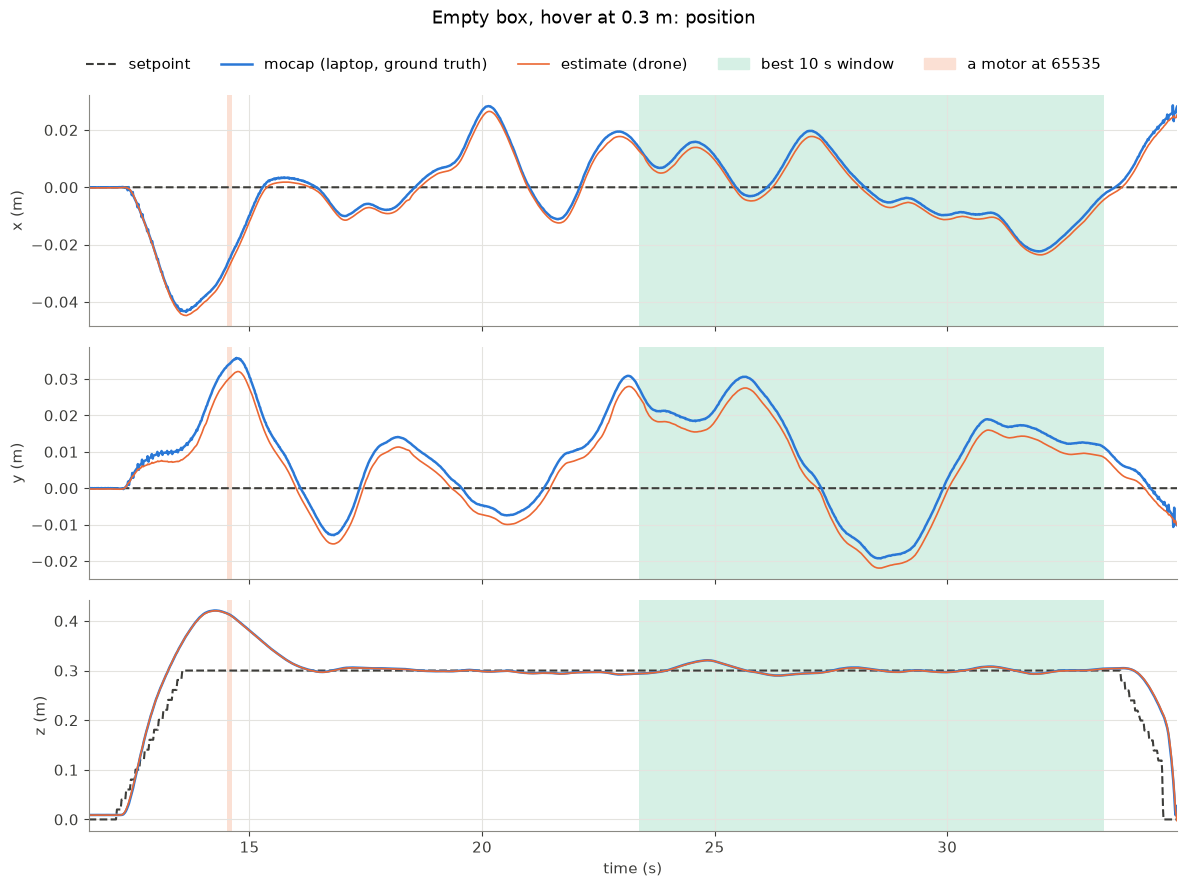

In [6]:
def shade(ax):
    ax.axvspan(best_t, best_t + WINDOW, color=C_SHADE_OK, zorder=0, lw=0)
    for a, b in sat_intervals:
        ax.axvspan(a, b, color=C_SHADE_BAD, zorder=0, lw=0)

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for k, (ax, name) in enumerate(zip(axes, ['x', 'y', 'z'])):
    shade(ax)
    ax.plot(t[span], p_des[span, k], '--', color=C_INK, lw=1.5, label='setpoint')
    ax.plot(t[span], p_mocap[span, k], color=C_BLUE, label='mocap (laptop, ground truth)')
    ax.plot(t[span], p_est[span, k], color=C_ORANGE, lw=1.2, label='estimate (drone)')
    ax.set_ylabel(f'{name} (m)')
axes[-1].set_xlabel('time (s)')
axes[-1].set_xlim(t0, t1)
handles, labels = axes[0].get_legend_handles_labels()
handles += [plt.Rectangle((0, 0), 1, 1, color=C_SHADE_OK), plt.Rectangle((0, 0), 1, 1, color=C_SHADE_BAD)]
labels += [f'best {WINDOW:.0f} s window', 'a motor at 65535']
fig.legend(handles, labels, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f'Empty box, hover at {z_hover} m: position', y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

### Error against the 5 cm requirement

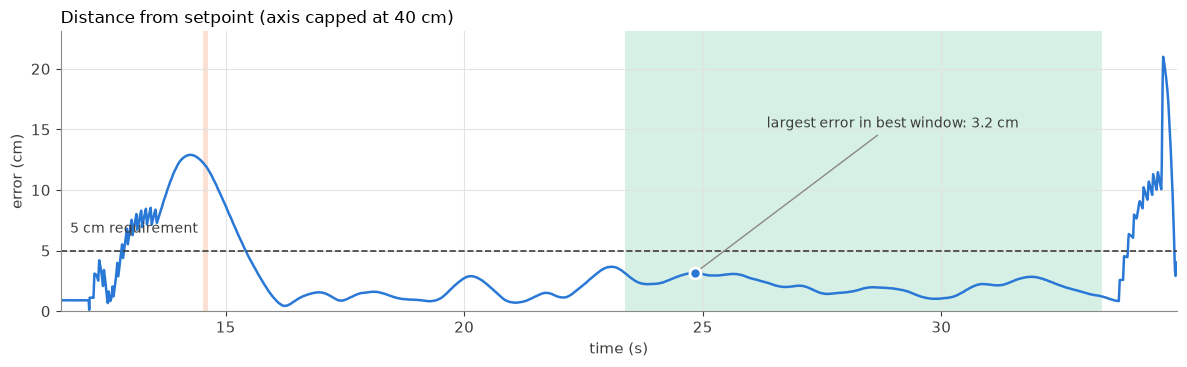

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.8))
shade(ax)
ax.plot(t[span], err[span] * 100, color=C_BLUE, label='3D error, mocap vs setpoint')
ax.axhline(TOL * 100, color=C_INK, ls='--', lw=1.2)
ax.text(t0 + 0.2, TOL * 100 + 1.2, f'{TOL * 100:.0f} cm requirement', color=C_INK, fontsize=10, va='bottom')
ax.plot(t[k_max], err[k_max] * 100, 'o', ms=8, color=C_BLUE, mec='white', mew=2, zorder=5)
ax.annotate(f'largest error in best window: {best_err * 100:.1f} cm', xy=(t[k_max], err[k_max] * 100),
            xytext=(t[k_max] + 1.5, err[k_max] * 100 + 12), color=C_INK, fontsize=10,
            arrowprops=dict(arrowstyle='-', color=C_MUTED, lw=1))
ax.set_ylim(0, min(np.nanmax(err[span]) * 100 * 1.1, 40))
ax.set_xlim(t0, t1)
ax.set_xlabel('time (s)')
ax.set_ylabel('error (cm)')
ax.set_title('Distance from setpoint (axis capped at 40 cm)', loc='left', fontsize=12)
plt.tight_layout()
plt.show()

### How the mocap observer performed

Top: estimate minus mocap as received by the drone, in millimetres. This is how closely the observer follows its measurement. Bottom: age of the latest mocap pose at each controller step (the firmware counts 500 Hz steps since the last pose; shown here in ms). Above 200 ms the observer would stop correcting.

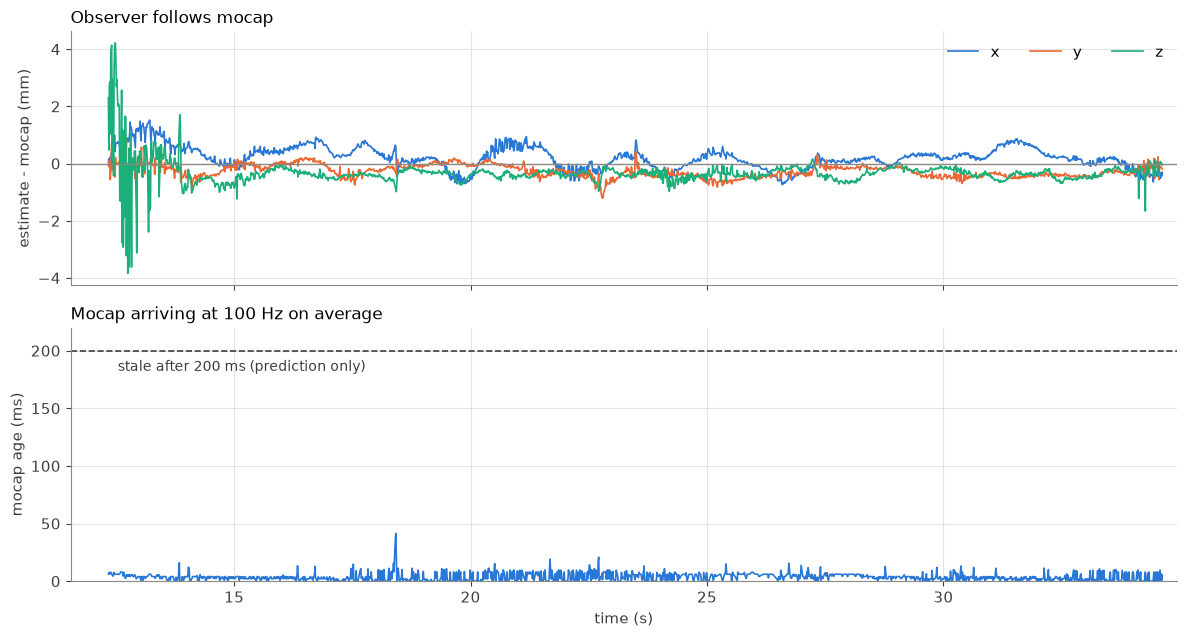

Estimate - mocap RMS in flight: x 0.4 mm, y 0.3 mm, z 0.6 mm
Mocap age in flight: median 3 ms, 99th percentile 12 ms, max 41 ms
Drone-received mocap vs laptop mocap RMS (3D): 3.2 mm


In [8]:
age_ms = log('mocap_age') * 2.0           # 500 Hz steps -> ms
n_mocap = log('num_mocap')
fly = span & (p_des[:, 2] > 0.05)
rate = (n_mocap[fly][-1] - n_mocap[fly][0]) / (t[fly][-1] - t[fly][0])

est_err_mm = (p_est - p_rx) * 1000
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for k, (name, c) in enumerate(zip(['x', 'y', 'z'], [C_BLUE, C_ORANGE, C_AQUA])):
    ax1.plot(t[fly], est_err_mm[fly, k], color=c, lw=1.2, label=name)
ax1.axhline(0, color=C_MUTED, lw=1)
ax1.set_ylabel('estimate - mocap (mm)')
ax1.legend(loc='upper right', ncol=3)
ax1.set_title('Observer follows mocap', loc='left', fontsize=12)

ax2.plot(t[fly], age_ms[fly], color=C_BLUE, lw=1.2)
ax2.axhline(200, color=C_INK, ls='--', lw=1.2)
ax2.text(t[fly][0] + 0.2, 192, 'stale after 200 ms (prediction only)', color=C_INK, fontsize=10, va='top')
ax2.set_ylim(0, 220)
ax2.set_ylabel('mocap age (ms)')
ax2.set_xlabel('time (s)')
ax2.set_title(f'Mocap arriving at {rate:.0f} Hz on average', loc='left', fontsize=12)
ax2.set_xlim(t0, t1)
plt.tight_layout()
plt.show()

rms = np.sqrt(np.nanmean(est_err_mm[fly] ** 2, axis=0))
print(f'Estimate - mocap RMS in flight: x {rms[0]:.1f} mm, y {rms[1]:.1f} mm, z {rms[2]:.1f} mm')
print(f'Mocap age in flight: median {np.median(age_ms[fly]):.0f} ms, 99th percentile '
      f'{np.percentile(age_ms[fly], 99):.0f} ms, max {np.max(age_ms[fly]):.0f} ms')
print(f'Drone-received mocap vs laptop mocap RMS (3D): '
      f'{np.sqrt(np.nanmean(np.sum((p_rx[fly] - p_mocap[fly]) ** 2, axis=1))) * 1000:.1f} mm')

### Motor commands and yaw

Motors 3 and 4 sit about 5000 above motors 1 and 2 during the steady hold, a constant roll torque that leaves motor 4 the least headroom. When motor 4 hits 65535 the controller loses yaw and thrust authority: yaw drifts and the drone sinks.

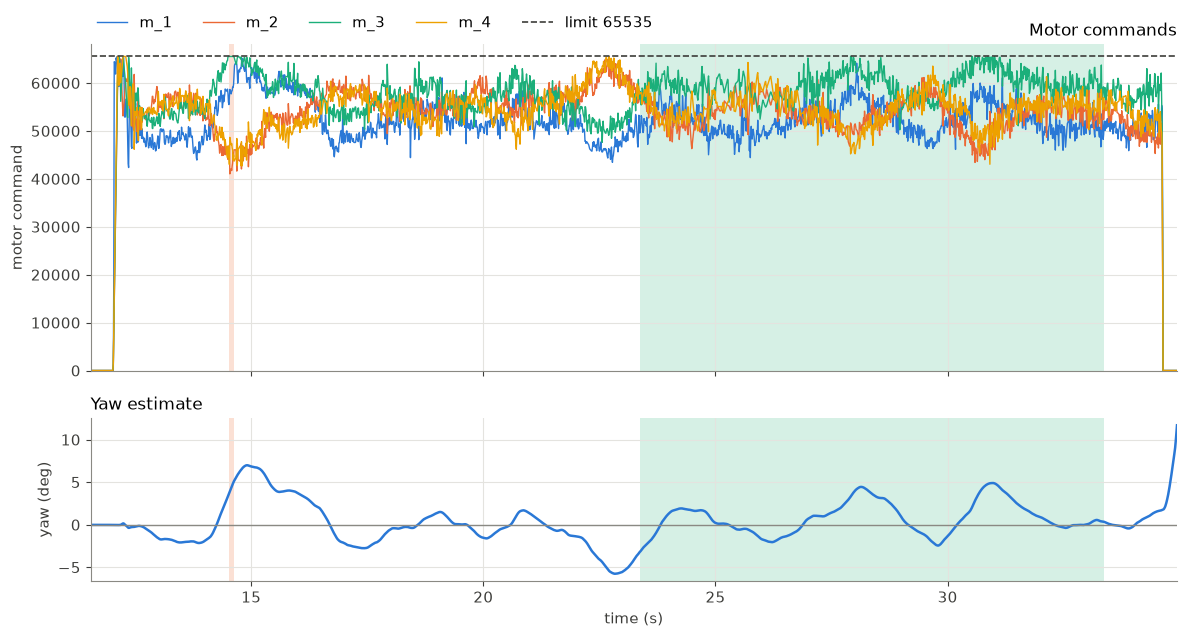

Mean motor commands in the best window (no saturation): m_1 52519, m_2 53490, m_3 59530, m_4 54555
Mean hover command: 55023 of 65535 (84%)
Mean f_z: 0.3286 N (gains eq_f_z = 0.3826 N)


In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for ax in (ax1, ax2):
    shade(ax)
for k, c in enumerate([C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]):
    ax1.plot(t[span], motors[span, k], color=c, lw=1.0, label=f'm_{k + 1}')
ax1.axhline(M_MAX, color=C_INK, ls='--', lw=1.2, label='limit 65535')
ax1.set_ylabel('motor command')
ax1.set_ylim(0, M_MAX * 1.04)
ax1.legend(loc='lower left', ncol=5, bbox_to_anchor=(0.0, 1.02), borderaxespad=0)
ax1.set_title('Motor commands', loc='right', fontsize=12)

ax2.plot(t[span], np.rad2deg(psi[span]), color=C_BLUE)
ax2.axhline(0, color=C_MUTED, lw=1)
ax2.set_ylabel('yaw (deg)')
ax2.set_xlabel('time (s)')
ax2.set_title('Yaw estimate', loc='left', fontsize=12)
ax2.set_xlim(t0, t1)
plt.tight_layout()
plt.show()

steady = hold & (t >= best_t) & (t < best_t + WINDOW) & ~sat
print('Mean motor commands in the best window (no saturation):',
      ', '.join(f'm_{k + 1} {v:.0f}' for k, v in enumerate(motors[steady].mean(axis=0))))
print(f'Mean hover command: {motors[steady].mean():.0f} of {M_MAX} ({motors[steady].mean() / M_MAX:.0%})')
print(f'Mean f_z: {log("f_z")[steady].mean():.4f} N (gains eq_f_z = {meta["gains"]["eq_f_z"]:.4f} N)')

### Top-down view during the hold

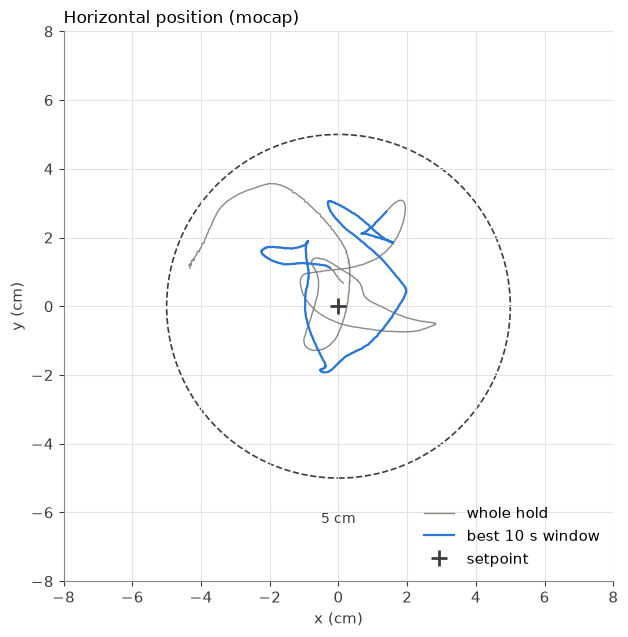

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
w = hold & (t >= best_t) & (t < best_t + WINDOW)
ax.plot(p_mocap[hold, 0] * 100, p_mocap[hold, 1] * 100, color=C_MUTED, lw=1, label='whole hold')
ax.plot(p_mocap[w, 0] * 100, p_mocap[w, 1] * 100, color=C_BLUE, lw=1.6, label=f'best {WINDOW:.0f} s window')
ax.add_patch(plt.Circle((0, 0), TOL * 100, fill=False, color=C_INK, ls='--', lw=1.2))
ax.plot(0, 0, '+', color=C_INK, ms=12, mew=2, label='setpoint')
ax.text(0, -TOL * 100 - 1, f'{TOL * 100:.0f} cm', ha='center', va='top', color=C_INK, fontsize=10)
lim = max(np.nanmax(np.abs(p_mocap[hold, :2])) * 100 * 1.1, TOL * 100 * 1.6)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect('equal')
ax.set_xlabel('x (cm)')
ax.set_ylabel('y (cm)')
ax.legend(loc='lower right')
ax.set_title('Horizontal position (mocap)', loc='left', fontsize=12)
plt.tight_layout()
plt.show()

### Summary: empty box, run 1

| | Result |
|---|---|
| Best 10 s window, max 3D error | 7.0 cm: **does not meet the 5 cm requirement** |
| Longest stretch within 5 cm | 9.6 s (t = 15.4 to 25.1 s), between the takeoff overshoot and motor 4 saturating: just short of 10 s |
| Estimate vs mocap | within about 1 mm: the mocap observer works on the drone |
| Mocap received | about 98 Hz in flight, typically 4 ms old (max 25 ms) |
| Hover motor command | about 85% of maximum, not the 98% the motor model predicted |
| Hover thrust | f_z about 0.332 N against eq_f_z = 0.3826 N in the gains, so takeoff overshot to 0.43 m and e_z wound up |
| Motor 4 saturation | about 3 s from t = 24.4 s: yaw drifted to -29 deg and the drone touched the floor |

**Changes for run 2:** set eq_f_z to the measured hover thrust (0.332 N), set eq_tau_x_cmd and eq_tau_y_cmd to the measured steady torques, check the box is centered and props 3 and 4 are OK, and land by holding at 5 cm before stopping.